# Run survey

What one run records, how it plots, and what is missing. Run against a cheap
`n = 1` run **before** the baseline, deliberately: a field that exists but is
never populated looks correct in the schema and is discovered empty during
analysis, when the executions have already been spent.

Three questions:

1. **Completeness** - is every column something writes?
2. **Shape** - what do the data support visually?
3. **Statistical readiness** - will the baseline *collect* what the §4.3
   comparisons need?

Not a pipeline stage. `03_baseline` is the baseline; this is the check before
paying for it.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().resolve().parents[1]))

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from src import survey, tables

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

# Pinned. Stored outputs describe one run; a selector that drifts leaves the
# prose describing numbers that are no longer below it.
RUN_ID = "42cab17a-4903-4e39-b00c-ace76b7929e4"

print(survey.headline(RUN_ID))

run 42cab17a  started 2026-09-23T17:52:07
  notes         FULL SUITE n=1 post-D74..D80 - verification
  agent         gemini-3.5-flash (released 2026-05-19)
  api           0.1.3 @ 5af96abf452b
  suite         031589fd9658
  executions    29  (+0 superseded)
  failed        0
  scored        29, mean 9.34
  cost          $0.6498


## 1. Completeness

`always null` with no stated reason means nothing writes the field.

In [2]:
gaps = survey.gaps(RUN_ID)
print(f"columns nothing wrote, with no stated reason: {len(gaps)}")
gaps[['rows', 'populated']] if len(gaps) else 'none'

columns nothing wrote, with no stated reason: 0


'none'

In [3]:
# The full picture, sparsest first. `expected` carries the reason a column is
# allowed to be empty; a blank reason on a low share is the thing to look at.
comp = survey.completeness(RUN_ID).sort_values("share")
comp[comp["share"] < 1.0]

rows  populated  share  always null                                           expected
table                     column                                                                                                          
study_runs                baseline_ref                 1          0   0.00         True         null on a baseline run by definition (D03)
study_case_executions     error                       29          0   0.00         True                    only a failed execution has one
study_scores              error                       29          0   0.00         True                 only an unscored execution has one
study_case_executions     structural_findings         29          0   0.00         True            only an execution with findings has any
study_suggestions         user_action                 35          0   0.00         True                       participant round only (D12)
                          structural_check_outcome    35          0   0.00         True  nothing writes it (D73): a structural verdict ...
study_user_actions        (whole table)                0          0   0.00         True  participant round only (D12) — the simulator d...
study_sessions            (whole table)                0          0   0.00         True                             participant round only
study_verdicts            (whole table)                0          0   0.00         True  no writer in either round after D73 — simulati...
study_survey_post_task    (whole table)                0          0   0.00         True                       participant round only (D02)
study_survey_demographics (whole table)                0          0   0.00         True                       participant round only (D02)
study_feedback            (whole table)                0          0   0.00         True  participant round only (§4.2.2) — thumbs come ...
study_suggestions         error_code                  35          0   0.00         True  only a FAILED turn has one; a clean run popula...
study_structural_verdicts findings                    29          0   0.00         True                   empty when the verdict is 'none'
study_mutations           changed_keys               358          5   0.01        False                    only an UPDATE has changed keys
                          origin_suggestion_id       358         10   0.03        False  only a mutation the AGENT caused has an origin...
study_suggestions         agent_intent                35         14   0.40        False              only a slash-command turn carries one
study_case_executions     expected_tool_sequence      29         14   0.48        False                                                   
                          base_case_id                29         18   0.62        False                                    seeds have none

## 2. Shape

`run_frame` is the join every question needs: execution + case metadata +
structural verdict + judge score, highest attempt only (D53).

In [4]:
runs = survey.run_frame(RUN_ID)
print(f"{len(runs)} executions, {runs['score'].notna().sum()} scored")
runs.head(8)

29 executions, 29 scored


,case,function,provenance,relation,repetition,attempt,error,blame,structural,findings,score,not_scored,latency_ms,cost_usd,tokens
0,advisory_packing_list,advisory,seeded,-,1,1,None,-,none,0,10,None,24681,0.036225,20065
1,advisory_packing_list__inv1_paraphrase,advisory,metamorphic,INV-1,1,1,None,-,none,0,10,None,124856,0.034714,19703
2,advisory_packing_list__inv3_irrelevant_detail,advisory,metamorphic,INV-3,1,1,None,-,none,0,7,None,62664,0.037055,20288
3,advisory_sintra_full_or_half_day,advisory,seeded,-,1,1,None,-,none,0,10,None,47548,0.020303,12075
4,advisory_sintra_full_or_half_day__inv1_paraphrase,advisory,metamorphic,INV-1,1,1,None,-,none,0,10,None,32077,0.020514,12151
5,advisory_sintra_full_or_half_day__inv4_german,advisory,metamorphic,INV-4,1,1,None,-,none,0,10,None,137755,0.030614,18284
6,factual_qa_alfama_history,factual_qa,seeded,-,1,1,None,-,none,0,10,None,36365,0.017477,10832
7,factual_qa_alfama_history__dir1_the_earthquake,factual_qa,metamorphic,DIR-1,1,1,None,-,none,0,10,None,11749,0.017093,10785


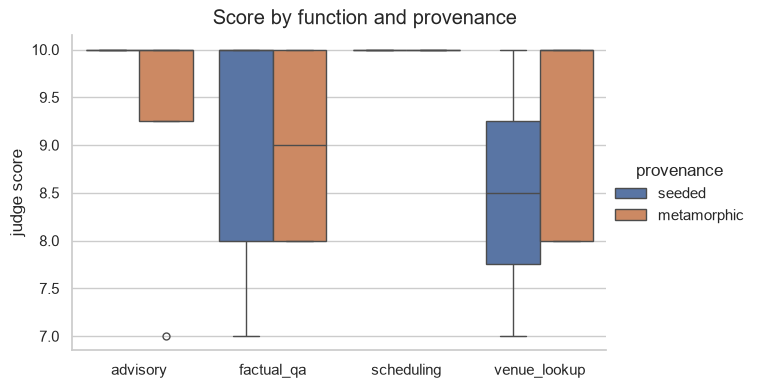

In [5]:
# Figure-level: seaborn picks the chart and facets it, which suits a dataset
# where nearly every question is "split by function or provenance".
scored = runs.dropna(subset=["score"])
if len(scored):
    g = sns.catplot(data=scored, x="function", y="score", hue="provenance",
                    kind="box", height=4, aspect=1.6)
    g.set_axis_labels("", "judge score")
    g.figure.suptitle("Score by function and provenance", y=1.02)
    plt.show()
else:
    print("no persisted scores for this run - see the completeness gaps above")

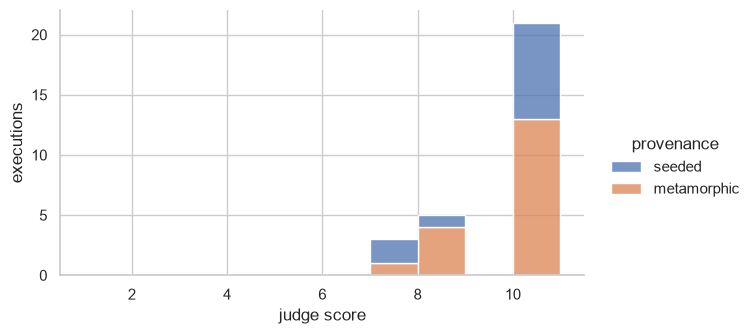

In [6]:
if len(scored):
    g = sns.displot(data=scored, x="score", hue="provenance", multiple="stack",
                    bins=range(1, 12), height=3.5, aspect=1.8)
    g.set_axis_labels("judge score", "executions")
    plt.show()

### Where the suite is slow, and why

Latency is read per population: a turn that waited on provider capacity is the
queue, not the agent (D60).

35 turns, 2 waited on capacity


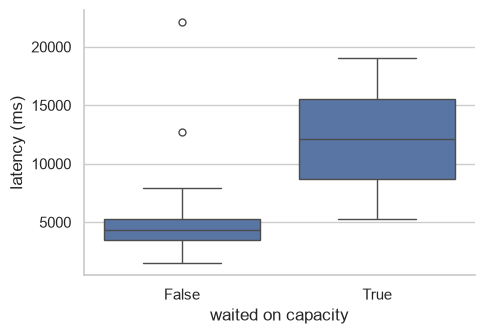

In [7]:
turns = survey.turn_frame(RUN_ID)
print(f"{len(turns)} turns, {int(turns['queued'].sum())} waited on capacity")

g = sns.catplot(data=turns, x="queued", y="latency_ms", kind="box",
                height=3.5, aspect=1.4)
g.set_axis_labels("waited on capacity", "latency (ms)")
plt.show()

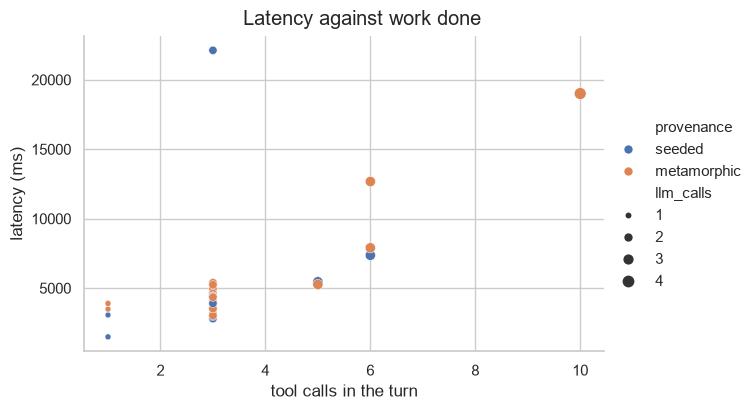

In [8]:
g = sns.relplot(data=turns, x="tool_calls", y="latency_ms", hue="provenance",
                size="llm_calls", height=4, aspect=1.6)
g.set_axis_labels("tool calls in the turn", "latency (ms)")
g.figure.suptitle("Latency against work done", y=1.02)
plt.show()

### Cost

In [9]:
by_case = runs.groupby("function")[["cost_usd", "tokens", "latency_ms"]].sum()
by_case["cost_share"] = (by_case["cost_usd"] / by_case["cost_usd"].sum()).round(3)
by_case.sort_values("cost_usd", ascending=False)

,cost_usd,tokens,latency_ms,cost_share
function,,,,
factual_qa,0.189139,116565,306308,0.291
advisory,0.179425,102566,429581,0.276
scheduling,0.157738,87409,254433,0.243
venue_lookup,0.123513,71791,220076,0.190


## 3. Coverage

Tool and relation coverage, from the same functions the run report uses - so
the notebook and the run log cannot disagree.

In [10]:
tables.tool_coverage(RUN_ID)

,cases requiring,cases permitting,calls,errors,all errored,parameters exercised
tool,,,,,,
get_climate_normals,1,6,1,0,False,"include_marine, lat, lng"
get_region_climate,0,6,6,0,False,place
get_weather,2,13,2,0,False,"end_date, lat, lng, start_date"
move_slot,2,2,2,0,False,"day_date, end_time, slot_id, start_time"
propose_plan,3,3,3,0,False,"days, description, title"
read_wikipedia,3,3,6,0,False,"query, section"
schedule_block,1,1,1,0,False,"block_id, day_date, start_time"
search_places,10,10,20,0,False,"lat, lng, query"
unschedule_block,1,1,1,0,False,slot_id


In [11]:
tables.relations()

,perturbation,kind,eligible seeds,follow-ups,share of opportunity
relation,,,,,
DIR-1,constraint added or changed,directional,9,5,0.556
DIR-2,day changed,directional,4,3,0.750
DIR-3,count changed,directional,4,1,0.250
DIR-4,negation,directional,4,2,0.500
INV-1,paraphrase,invariance,11,4,0.364
INV-2,typos and casing,invariance,11,1,0.091
INV-3,irrelevant detail added,invariance,11,1,0.091
INV-4,language switch (German),invariance,11,1,0.091


## 4. Statistical readiness

The point of running this before the baseline: the tests §4.3 needs have to be
*collectable* from what a run records. Checked here against real columns rather
than assumed.

In [12]:
from scipy import stats
from statsmodels.stats.proportion import proportion_confint

checks = []

# Unit of analysis: one execution, independent by construction - each
# repetition builds its own trip (D38), so repetitions of a case are draws.
checks.append(("unit of analysis", "execution", "repetitions are independent (D38: a trip per repetition)"))

# A pass rate needs a binary outcome per execution. Structural gives one.
structural = runs["structural"].value_counts().to_dict()
have_structural = runs["structural"].ne("(not checked)").all()
checks.append(("binary outcome per execution", str(structural),
               "present" if have_structural else "MISSING - run the checker before the baseline"))

# A confidence interval on a rate needs successes and trials.
passes = int((runs["structural"] == "none").sum())
n = len(runs)
if have_structural and n:
    lo, hi = proportion_confint(passes, n, method="wilson")
    checks.append(("Wilson CI on the pass rate", f"{passes}/{n}", f"[{lo:.2f}, {hi:.2f}]"))

# Paired comparison between two runs needs the same cases in both.
checks.append(("paired test (McNemar / Wilcoxon)", "needs 2 runs over the same suite_version",
               "baseline vs regression run - B10 then B11"))

# Score comparison needs scores persisted, which is what study_scores is for.
checks.append(("score comparison (Wilcoxon signed-rank)",
               f"{runs['score'].notna().sum()} scores persisted this run",
               "needs both runs scored; study_scores makes that joinable (D71)"))

pd.DataFrame(checks, columns=["what", "observed", "status"])

,what,observed,status
0,unit of analysis,execution,repetitions are independent (D38: a trip per r...
1,binary outcome per execution,{'none': 29},present
2,Wilson CI on the pass rate,29/29,"[0.88, 1.00]"
3,paired test (McNemar / Wilcoxon),needs 2 runs over the same suite_version,baseline vs regression run - B10 then B11
4,score comparison (Wilcoxon signed-rank),29 scores persisted this run,needs both runs scored; study_scores makes tha...


In [13]:
# What n = 1 cannot support, stated rather than discovered later.
per_case = runs.groupby("case").size()
print(f"repetitions per case: min {per_case.min()}, max {per_case.max()}")
print()
print("At n = 1 a per-case pass rate is 0 or 1 - no distribution, no variance,")
print("and D23's 8/8 seed criterion is not evaluable. The baseline runs seeds")
print("at n = 8 and follow-ups at n = 4 (D21), which is what makes a per-case")
print("rate and a paired test possible at all.")

repetitions per case: min 1, max 1

At n = 1 a per-case pass rate is 0 or 1 - no distribution, no variance,
and D23's 8/8 seed criterion is not evaluable. The baseline runs seeds
at n = 8 and follow-ups at n = 4 (D21), which is what makes a per-case
rate and a paired test possible at all.


## 5. What this found

Filled in after running. The value of the notebook is this list, not the
plots.

In [14]:
findings = []
if len(gaps):
    findings += [f"column never written: {t}.{c}" for t, c in gaps.index]
if not have_structural:
    findings.append("structural verdicts absent - the checker had not run over this run")
if runs["score"].notna().sum() == 0:
    findings.append("no persisted judge scores - scores existed only in memory before D71")
if turns.empty:
    findings.append("no turn-level rows joined - check suggestion_ids on the executions")

print("\n".join(f"- {f}" for f in findings) if findings else "- nothing outstanding")

- nothing outstanding
